# Final model: a 4.85M-parameter Wide ResNet for CIFAR-10

**Team Whatever** · Idriss Malek (im2868) · NYU Deep Learning, Fall 2026, Project 1

This notebook shows **run 58**, one of our two final submissions: a pre-activation **WRN-22** with **4,851,866 trainable parameters**, trained from scratch on the 50,000 CIFAR-10 training images. It learned from the labels and from the averaged outputs of four larger teachers, which we also trained from scratch on the same images.

- **Part 1** loads the model (or retrains it), evaluates it on the 10,000-image CIFAR-10 test set and shows what it gets right and wrong.
- **Part 2** rebuilds the tables and figures of the report from our training logs (`logs/`) and analysis tables (`results/`).

| Mode | What happens |
|---|---|
| `TRAIN = False` (default) | loads `checkpoints/58_wrn22_w68_full_t35_38_55_56_600ep_sqrtw.pt`; the whole notebook runs in about a minute on a GPU |
| `TRAIN = True` | retrains the model from random weights with the command used for the submission (about 3.5 hours on an A100), then evaluates the new weights; needs the four teacher checkpoints (see the README) |

Nothing in this notebook uses the Kaggle test images.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

import src.figures as figures
from src.figures import AXIS, BLUE, GRID, INK, ORANGE, SECONDARY, TIE, latest, summary, test_tta
from src.data import CLASSES, cifar10, load_cifar10
from src.models import count_parameters, load_checkpoint
from src.train import predict

%config InlineBackend.figure_format = "retina"
STYLE = {"font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
         "axes.titlepad": 8}
TEACHER_NAMES = {"34": "SAM-1", "35": "SAM-2", "37": "SimCLR", "38": "LeJEPA", "55": "SAM-AA", "56": "CCT"}


def show(table, caption=None, formats=None, best_in_column=None, best_in_row=None, left=None):
    # A table in the notebook's style; the best value of the given columns, or of each row, is in bold
    styler = table.style.hide(axis="index").format(formats or {}, precision=2, thousands=",", na_rep="–")
    for column in best_in_column or []:
        styler = styler.highlight_max(subset=[column], props="font-weight: 700")
    if best_in_row:
        styler = styler.highlight_max(subset=best_in_row, axis=1, props="font-weight: 700")
    if left:
        styler = styler.set_properties(subset=left, **{"text-align": "left !important"})
    styler = styler.set_table_styles([
        {"selector": "", "props": "border-collapse: collapse; font-size: 12.5px; margin: 4px 0 18px 0;"},
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; padding-bottom: 8px;"},
        {"selector": "th", "props": f"background: #f4f3ee; color: {INK}; font-weight: 600; text-align: center; "
                                    f"padding: 6px 14px; border-bottom: 1.5px solid {AXIS};"},
        {"selector": "td", "props": "text-align: center; padding: 5px 14px; border-bottom: 1px solid #e9e8e2;"},
        {"selector": "th:first-child, td:first-child", "props": "text-align: left;"},
    ])
    display(styler.set_caption(caption) if caption else styler)


def show_figure(fig, dpi=150):
    # The report's figures are sized for a two-column page; a higher dpi makes them readable here
    fig.set_dpi(dpi)
    display(fig)
    plt.close(fig)

## Part 1 · The final model

### Load or train

In [2]:
TRAIN = False  # True: retrain run 58 from random weights with the command used for the submission

NAME = "58_wrn22_w68_full_t35_38_55_56_600ep_sqrtw"
TEACHERS = ["35_teacher_wrn28_10_sam_seed1_full", "38_teacher_wrn28_10_lejepa_full",
            "55_teacher_wrn28_10_sampaper_seed0", "56_teacher_cct7_3x1_sine_full"]
SAMPLE_WEIGHTS = "results/subgroups_38_teacher_wrn28_10_lejepa_full/20261030-213616/train_subgroups.csv"

if TRAIN:
    missing = [t for t in TEACHERS if not os.path.exists(f"checkpoints/{t}.pt")]
    assert not missing, f"train these teachers first (README, 'Training every model'): {missing}"
    NAME = "58_wrn22_w68_retrained"
    command = (f"python -m scripts.train_student --name {NAME} --arch wrn22_w68 --epochs 600 --full-train "
               f"--teacher {' '.join(TEACHERS)} --sample-weights {SAMPLE_WEIGHTS}")
    print(command)
    get_ipython().system(command)

model = load_checkpoint(NAME)
hyp = torch.load(f"checkpoints/{NAME}.pt", weights_only=True)["hyp"]
log = summary(NAME)
print(f"{'Trained' if TRAIN else 'Loaded'} checkpoints/{NAME}.pt")

Loaded checkpoints/58_wrn22_w68_full_t35_38_55_56_600ep_sqrtw.pt


### Size and architecture

A pre-activation Wide ResNet: a 3×3 stem, then three stages of three residual blocks. Each block applies BatchNorm, ReLU and a 3×3 convolution twice, plus a skip connection; stages 2 and 3 halve the resolution, and a 1×1 convolution projects the skip connection when the shape changes. The model is defined in `src/models.py` (`PreActResNet`, entry `wrn22_w68` of `STUDENTS`).

In [3]:
n_trainable, n_total = count_parameters(model)
assert n_total <= 5_000_000
print(f"Trainable parameters: {n_trainable:,}  (limit: 5,000,000)")


def n_params(module):
    return sum(p.numel() for p in module.parameters())


stages = {}
for block in model.blocks:
    stages.setdefault(block.conv2.out_channels, []).append(block)
parts = [("Stem", f"3×3 convolution, {model.stem.out_channels} channels", "32×32", n_params(model.stem))]
for i, (channels, blocks) in enumerate(stages.items()):
    parts.append((f"Stage {i + 1}", f"{len(blocks)} residual blocks, {channels} channels", f"{32 >> i}×{32 >> i}",
                  sum(n_params(b) for b in blocks)))
parts.append(("Head", "BatchNorm, ReLU, global average pooling, linear layer", "1×1",
              n_params(model.bn) + n_params(model.head)))
parts.append(("Total", "", "", n_trainable))
show(pd.DataFrame(parts, columns=["Part", "Layers", "Resolution", "Parameters"]), "WRN-22 student", left=["Layers"])

Trainable parameters: 4,851,866  (limit: 5,000,000)


Part,Layers,Resolution,Parameters
Stem,"3×3 convolution, 16 channels",32×32,432
Stage 1,"3 residual blocks, 68 channels",32×32,"219,672"
Stage 2,"3 residual blocks, 136 channels",16×16,"926,296"
Stage 3,"3 residual blocks, 272 channels",8×8,"3,702,192"
Head,"BatchNorm, ReLU, global average pooling, linear layer",1×1,"3,274"
Total,,,"4,851,866"


### Training configuration

Read from the checkpoint itself, so this is the configuration that produced these weights. The recipe is implemented in `scripts/train_student.py` and `src/train.py`.

In [4]:
teachers = ", ".join(f"{TEACHER_NAMES.get(t[:2], t)}" for t in hyp["teacher"])
config = [
    ("Optimizer", f"SGD with Nesterov momentum {hyp['momentum']}"),
    ("Learning rate", f"{hyp['lr']}, {hyp['warmup_epochs']} warm-up epochs, then cosine decay"),
    ("Batch size", f"{hyp['batch_size']}"),
    ("Epochs", f"{hyp['epochs']}"),
    ("Weight decay", f"{hyp['weight_decay']:g}"),
    ("Augmentation", f"flips, {hyp['translate']}-pixel translations, Cutout {hyp['cutout']}, Mixup (α = "
                     f"{hyp['mixup_alpha']}) or CutMix (α = {hyp['cutmix_alpha']:g}), one of the two per batch"),
    ("Weight averaging", f"exponential moving average of the weights, decay {hyp['ema_decay']}"),
    ("Loss", f"{1 - hyp['kd_weight']:.1f} × cross-entropy + {hyp['kd_weight']} × distillation, "
             f"temperature {hyp['kd_temperature']:g}"),
    ("Teachers (logits averaged)", f"{teachers}, all trained from scratch on CIFAR-10"),
    ("Sampling", "each image drawn with probability ∝ 1 / √(size of its subgroup)"),
    ("Training images", "all 50,000; the test set was only logged, never trained on" if hyp["full_train"]
     else "45,000"),
]
show(pd.DataFrame(config, columns=["Setting", "Value"]), "Training configuration stored in the checkpoint",
     left=["Value"])

Setting,Value
Optimizer,SGD with Nesterov momentum 0.9
Learning rate,"0.1, 5 warm-up epochs, then cosine decay"
Batch size,128
Epochs,600
Weight decay,0.0005
Augmentation,"flips, 4-pixel translations, Cutout 16, Mixup (α = 0.8) or CutMix (α = 1), one of the two per batch"
Weight averaging,"exponential moving average of the weights, decay 0.999"
Loss,"0.1 × cross-entropy + 0.9 × distillation, temperature 4"
Teachers (logits averaged),"SAM-2, LeJEPA, SAM-AA, CCT, all trained from scratch on CIFAR-10"
Sampling,each image drawn with probability ∝ 1 / √(size of its subgroup)


### Training log

The log of the run that produced the checkpoint (`logs/<run>/<run_id>/epochs.csv`). Training starts from random weights: after the first epoch the network classifies about half of the test images correctly, and the moving average of its weights, which starts from the random initialisation, only 13%. The test set was evaluated after every epoch for monitoring and was never used for training.

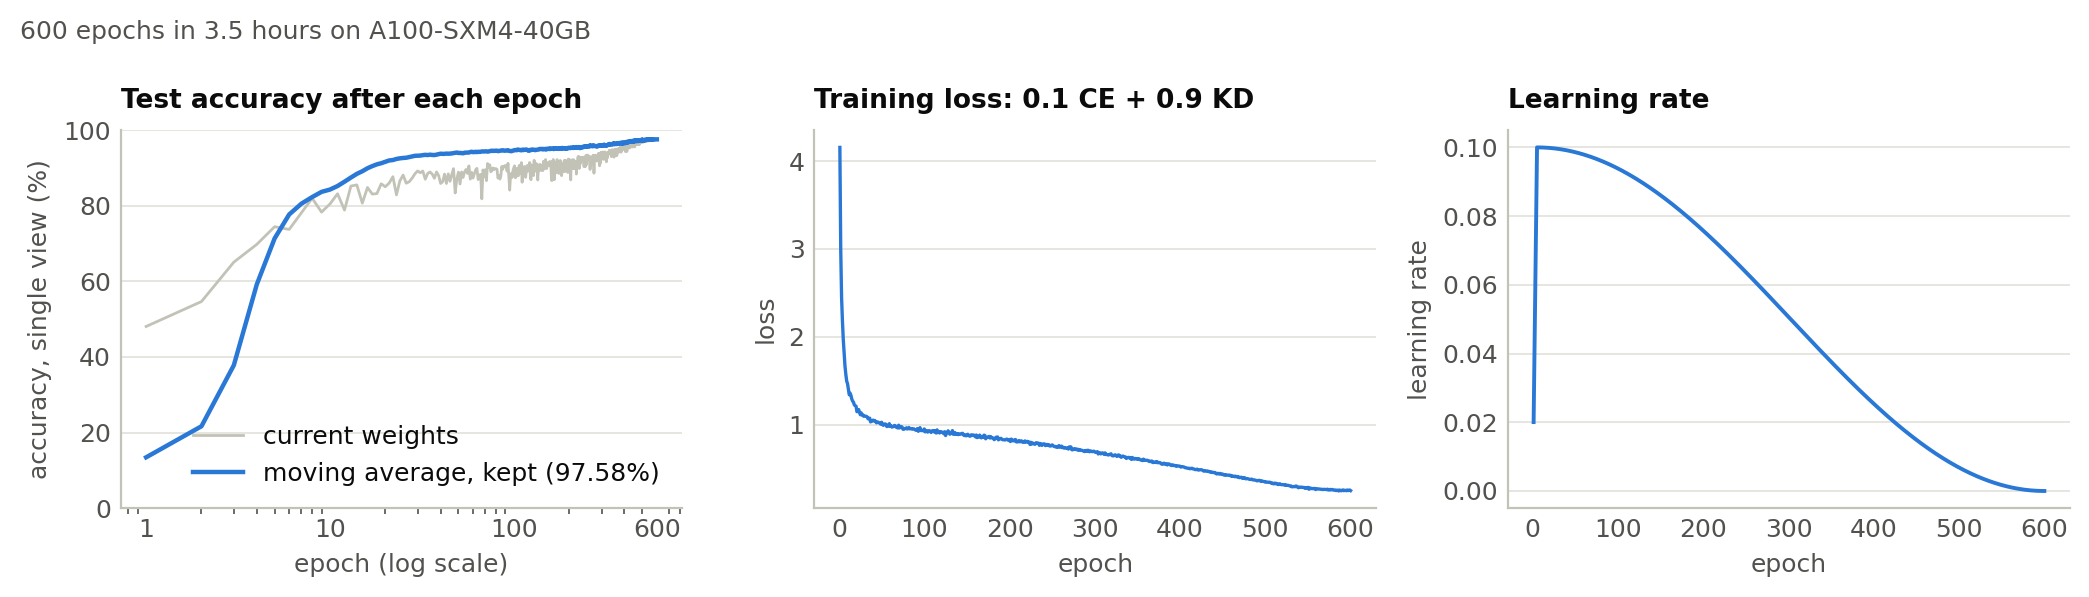

In [5]:
epochs = pd.read_csv(sorted(glob.glob(f"logs/{NAME}/*/epochs.csv"))[-1])
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0))
    ax = axes[0]
    ax.plot(epochs.epoch, 100 * epochs.raw_val_acc, color=TIE, lw=1, label="current weights")
    ax.plot(epochs.epoch, 100 * epochs.val_acc, color=BLUE, lw=1.6,
            label=f"moving average, kept ({100 * epochs.val_acc.iloc[-1]:.2f}%)")
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 100, len(epochs)], [1, 10, 100, len(epochs)])
    ax.set_ylim(0, 100)
    ax.set(title="Test accuracy after each epoch", xlabel="epoch (log scale)", ylabel="accuracy, single view (%)")
    ax.legend(loc="lower right")
    ax = axes[1]
    ax.plot(epochs.epoch, epochs.train_loss, color=BLUE, lw=1.2)
    ax.set(title="Training loss: 0.1 CE + 0.9 KD", xlabel="epoch", ylabel="loss")
    ax = axes[2]
    ax.plot(epochs.epoch, epochs.lr, color=BLUE, lw=1.4)
    ax.set(title="Learning rate", xlabel="epoch", ylabel="learning rate")
    hours = log["train_time_s"] / 3600
    fig.suptitle(f"{len(epochs)} epochs in {hours:.1f} hours on {log['gpu'].replace('NVIDIA ', '')}",
                 x=0.01, ha="left", fontsize=9, color=SECONDARY)
    fig.tight_layout()
    plt.show()

### Test-set evaluation

Accuracy with a single view, and with the six-view test-time augmentation (TTA) used throughout the report: flips and one-pixel shifts, with logits averaged. The last row is the accuracy written to the training log when the run ended, on an A100, as a check that this checkpoint is the logged model; a difference of an image or two comes from floating-point arithmetic on a different GPU.

In [6]:
test_x, test_y = load_cifar10("data", val_size=0, seed=0)["test"]
single = predict(model, test_x).float().cpu()
logits = predict(model, test_x, tta=True).float().cpu()
confidence, prediction = logits.softmax(1).max(1)
correct = prediction == test_y

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (test_y.numpy(), prediction.numpy()), 1)
recall = confusion.diagonal() / confusion.sum(1)
precision = confusion.diagonal() / confusion.sum(0)
f1 = 2 * precision * recall / (precision + recall)


def calibration_error(confidence, correct, bins=15):
    # Expected calibration error: average |accuracy - confidence| over equal-width confidence bins
    edges, error = torch.linspace(0, 1, bins + 1), 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        inside = (confidence > low) & (confidence <= high)
        if inside.any():
            error += inside.float().mean() * (confidence[inside].mean() - correct[inside].float().mean()).abs()
    return float(error)


accuracy = 100 * correct.float().mean().item()
metrics = [
    ("Test accuracy, single view", f"{100 * (single.argmax(1) == test_y).float().mean():.2f}%"),
    ("Test accuracy, TTA", f"{accuracy:.2f}%"),
    ("Misclassified test images, TTA", f"{(~correct).sum().item()} of {len(test_y):,}"),
    ("Top-2 accuracy, TTA", f"{100 * (logits.topk(2).indices == test_y[:, None]).any(1).float().mean():.2f}%"),
    ("Mean precision / recall / F1 over classes", f"{100 * precision.mean():.2f}% / {100 * recall.mean():.2f}% / "
                                                  f"{100 * f1.mean():.2f}%"),
    ("Cross-entropy, TTA", f"{F.cross_entropy(logits, test_y):.4f}"),
    ("Expected calibration error, TTA (15 bins)", f"{100 * calibration_error(confidence, correct):.2f}%"),
    ("Test accuracy, TTA, written to the training log", f"{100 * log['test_tta_acc']:.2f}%"),
    ("GPU used for this evaluation", torch.cuda.get_device_name(0)),
]
show(pd.DataFrame(metrics, columns=["Metric", "Value"]), "CIFAR-10 test set, 10,000 images")
print(f"FINAL TEST ACCURACY (TTA): {accuracy:.2f}%   |   TRAINABLE PARAMETERS: {n_trainable:,}")

Metric,Value
"Test accuracy, single view",97.59%
"Test accuracy, TTA",97.73%
"Misclassified test images, TTA","227 of 10,000"
"Top-2 accuracy, TTA",99.51%
Mean precision / recall / F1 over classes,97.73% / 97.73% / 97.73%
"Cross-entropy, TTA",0.0695
"Expected calibration error, TTA (15 bins)",0.42%
"Test accuracy, TTA, written to the training log",97.74%
GPU used for this evaluation,NVIDIA GeForce RTX 4070 Laptop GPU


FINAL TEST ACCURACY (TTA): 97.73%   |   TRAINABLE PARAMETERS: 4,851,866


### Where the errors are

Left: where the misclassified test images go. Off-diagonal cells count errors; the diagonal gives each class's accuracy in %. Right: recall (accuracy on the class) and precision for each class.

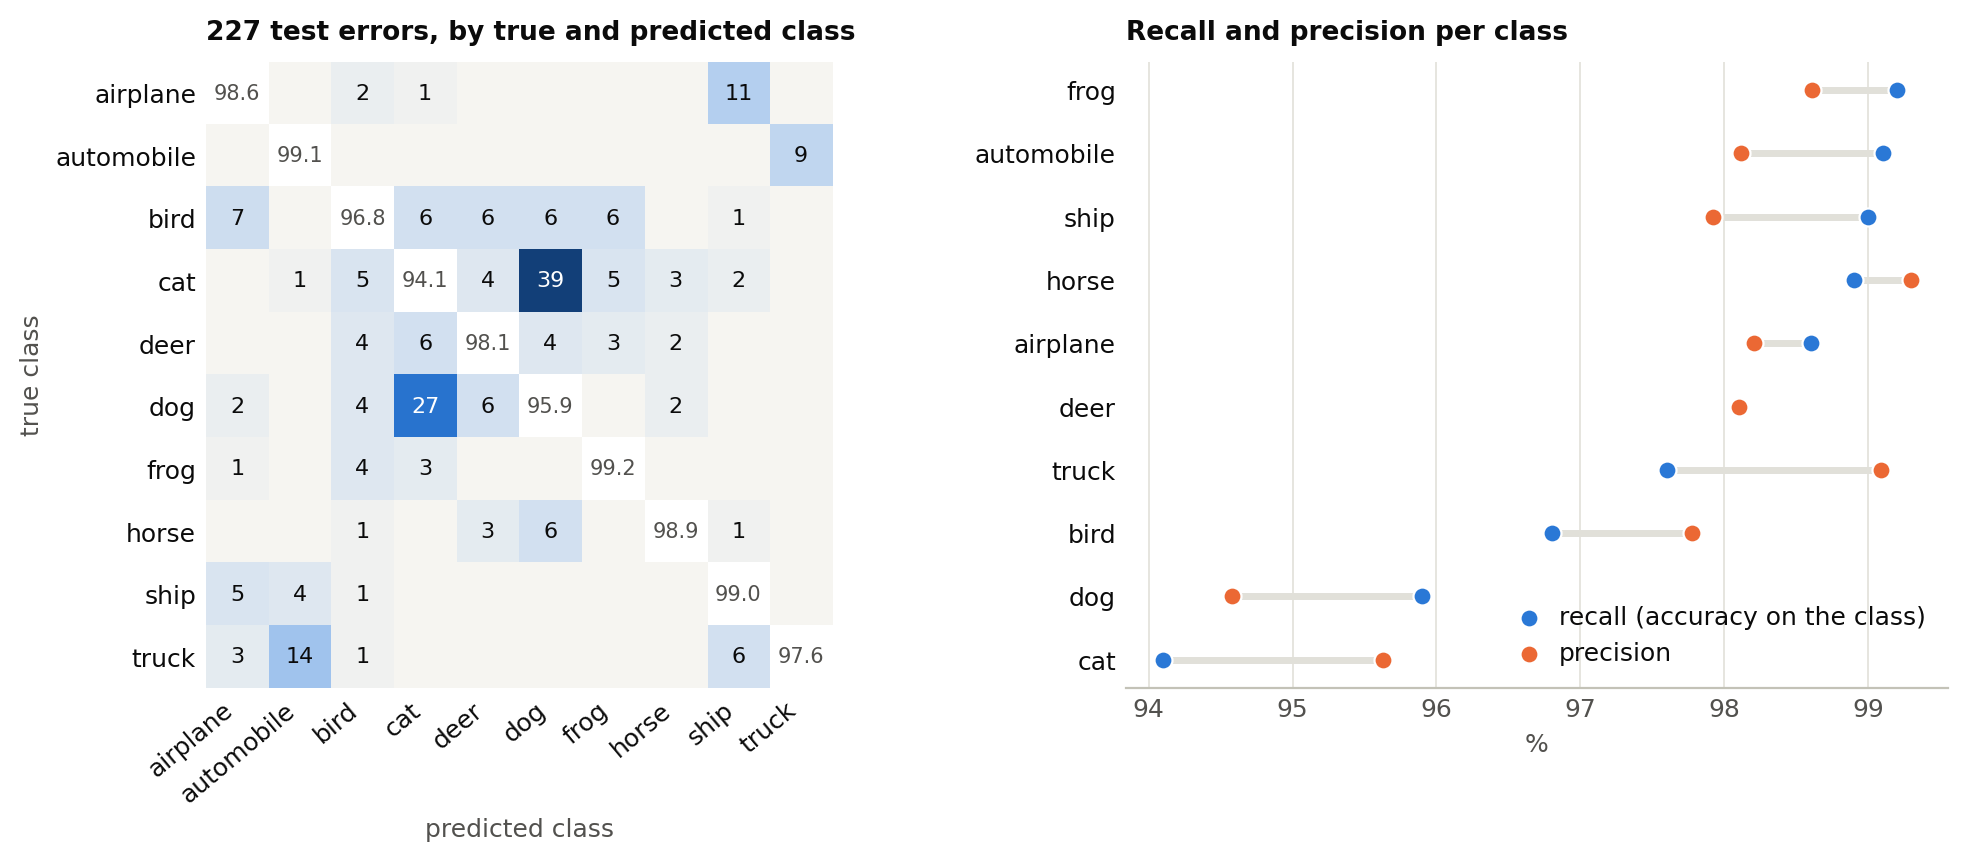

In [7]:
errors = confusion.astype(float)
np.fill_diagonal(errors, np.nan)
cmap = LinearSegmentedColormap.from_list("errors", ["#f6f5f1", "#a9c9ef", BLUE, "#123f78"])
with plt.rc_context(STYLE):
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
    ax.imshow(errors, cmap=cmap, vmin=0)
    top = np.nanmax(errors)
    for i in range(10):
        for j in range(10):
            if i == j:
                ax.text(j, i, f"{100 * recall[i]:.1f}", ha="center", va="center", fontsize=7.5, color=SECONDARY)
            elif confusion[i, j]:
                ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=8,
                        color="white" if confusion[i, j] > 0.45 * top else INK)
    ax.set_xticks(range(10), CLASSES, rotation=40, ha="right")
    ax.set_yticks(range(10), CLASSES)
    ax.tick_params(colors=INK)
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set(title=f"{(~correct).sum().item()} test errors, by true and predicted class", xlabel="predicted class",
           ylabel="true class")

    order = np.argsort(recall)
    y = np.arange(10)
    bx.hlines(y, 100 * np.minimum(recall, precision)[order], 100 * np.maximum(recall, precision)[order],
              color=GRID, lw=2.5, zorder=1)
    bx.scatter(100 * recall[order], y, s=42, color=BLUE, edgecolor="white", lw=0.8, zorder=3,
               label="recall (accuracy on the class)")
    bx.scatter(100 * precision[order], y, s=42, color=ORANGE, edgecolor="white", lw=0.8, zorder=3,
               label="precision")
    bx.set_yticks(y, [CLASSES[i] for i in order])
    bx.tick_params(axis="y", colors=INK)
    bx.grid(axis="y", visible=False)
    bx.grid(axis="x", color=GRID, lw=0.6)
    bx.spines["left"].set_visible(False)
    bx.set_xlabel("%")
    bx.set_title("Recall and precision per class")
    bx.legend(loc="lower right", handletextpad=0.2)
    fig.tight_layout()
    plt.show()

### Confidence and calibration

Confidence is the largest softmax probability after TTA. Left: accuracy against confidence in nine equal-width bins; on the dashed diagonal, confidence would equal accuracy, and point area shows how many test images fall in each bin. Right: confidence of correct and wrong predictions.

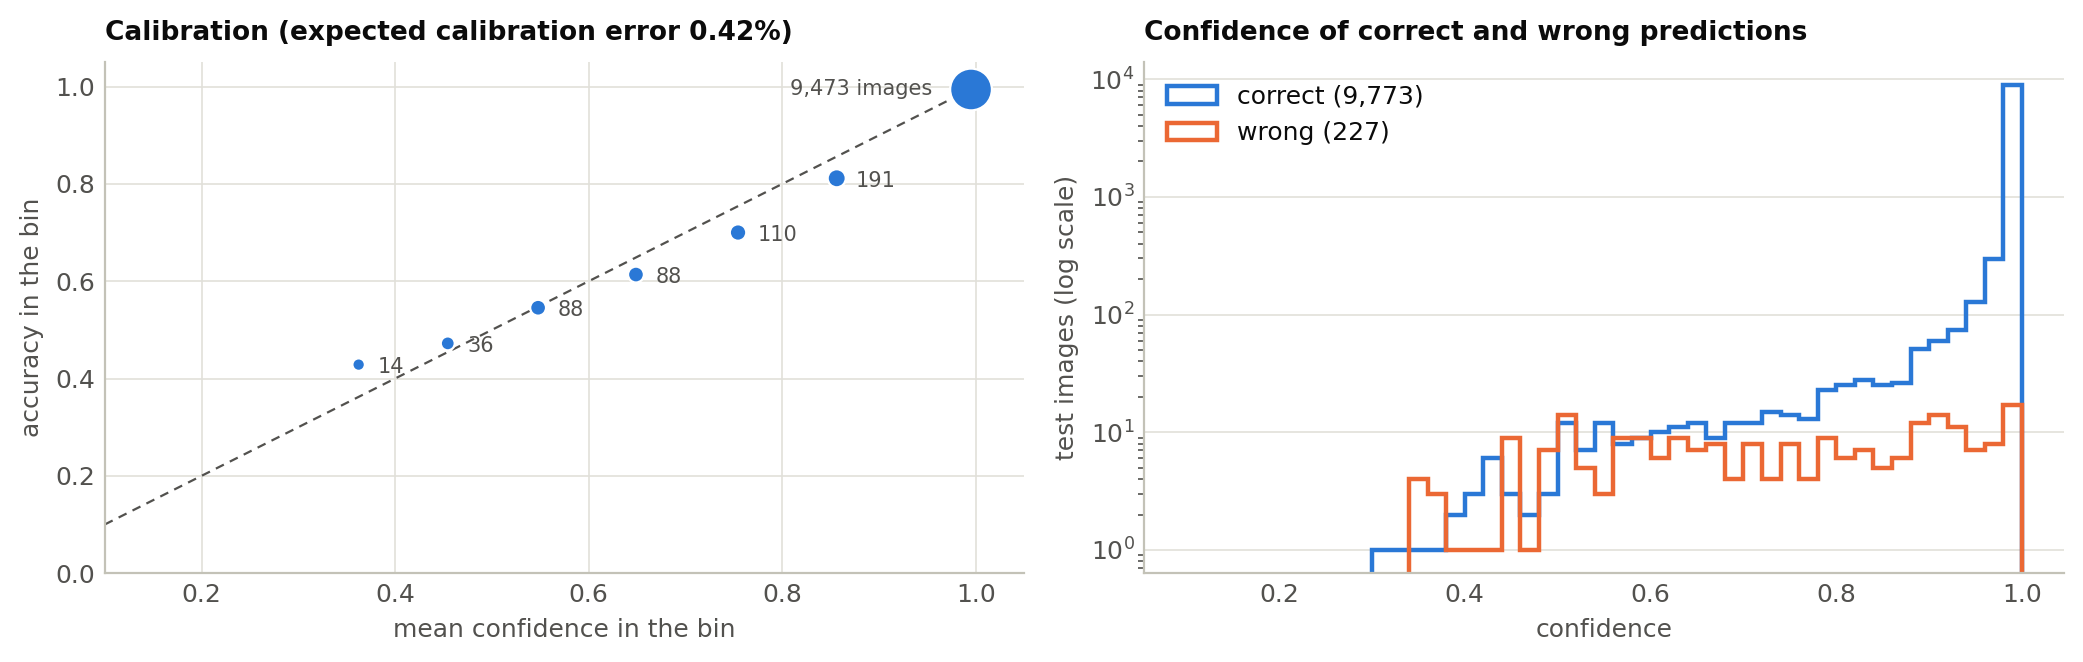

In [8]:
conf, ok = confidence.numpy(), correct.numpy()
edges = np.linspace(0.1, 1.0, 10)
bins = np.clip(np.digitize(conf, edges) - 1, 0, len(edges) - 2)
reliability = pd.DataFrame([(conf[bins == b].mean(), ok[bins == b].mean(), (bins == b).sum())
                            for b in range(len(edges) - 1) if (bins == b).any()],
                           columns=["confidence", "accuracy", "images"])
with plt.rc_context(STYLE):
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.4))
    ax.plot([0.1, 1], [0.1, 1], color=SECONDARY, lw=0.8, ls=(0, (4, 3)))
    ax.scatter(reliability.confidence, reliability.accuracy, s=12 + 2.2 * np.sqrt(reliability.images), color=BLUE,
               edgecolor="white", lw=0.8, zorder=3)
    for _, row in reliability.iterrows():
        last = row.confidence > 0.95
        ax.annotate(f"{row.images:,.0f} images" if last else f"{row.images:,.0f}", (row.confidence, row.accuracy),
                    xytext=(-14, 0) if last else (7, -3), ha="right" if last else "left", va="center" if last else "baseline",
                    textcoords="offset points", fontsize=7.5, color=SECONDARY)
    ax.grid(axis="x", color=GRID, lw=0.6)
    ax.set(xlim=(0.1, 1.05), ylim=(0, 1.05), xlabel="mean confidence in the bin", ylabel="accuracy in the bin",
           title=f"Calibration (expected calibration error {100 * calibration_error(confidence, correct):.2f}%)")
    hist_bins = np.linspace(0.1, 1, 46)
    bx.hist(conf[ok], bins=hist_bins, histtype="step", lw=1.6, color=BLUE, label=f"correct ({ok.sum():,})")
    bx.hist(conf[~ok], bins=hist_bins, histtype="step", lw=1.6, color=ORANGE, label=f"wrong ({(~ok).sum():,})")
    bx.set_yscale("log")
    bx.set(xlabel="confidence", ylabel="test images (log scale)", title="Confidence of correct and wrong predictions")
    bx.legend(loc="upper left")
    fig.tight_layout()
    plt.show()

### The most confident mistakes

The 24 test images that the model misclassifies with the highest confidence, labelled *true class → predicted class* and confidence. For the submitted checkpoint, many are automobile/truck pairs, where the two classes overlap (pickups, vans), or cat/dog pairs, and some labels look wrong: the first image, labelled *cat*, shows a frog.

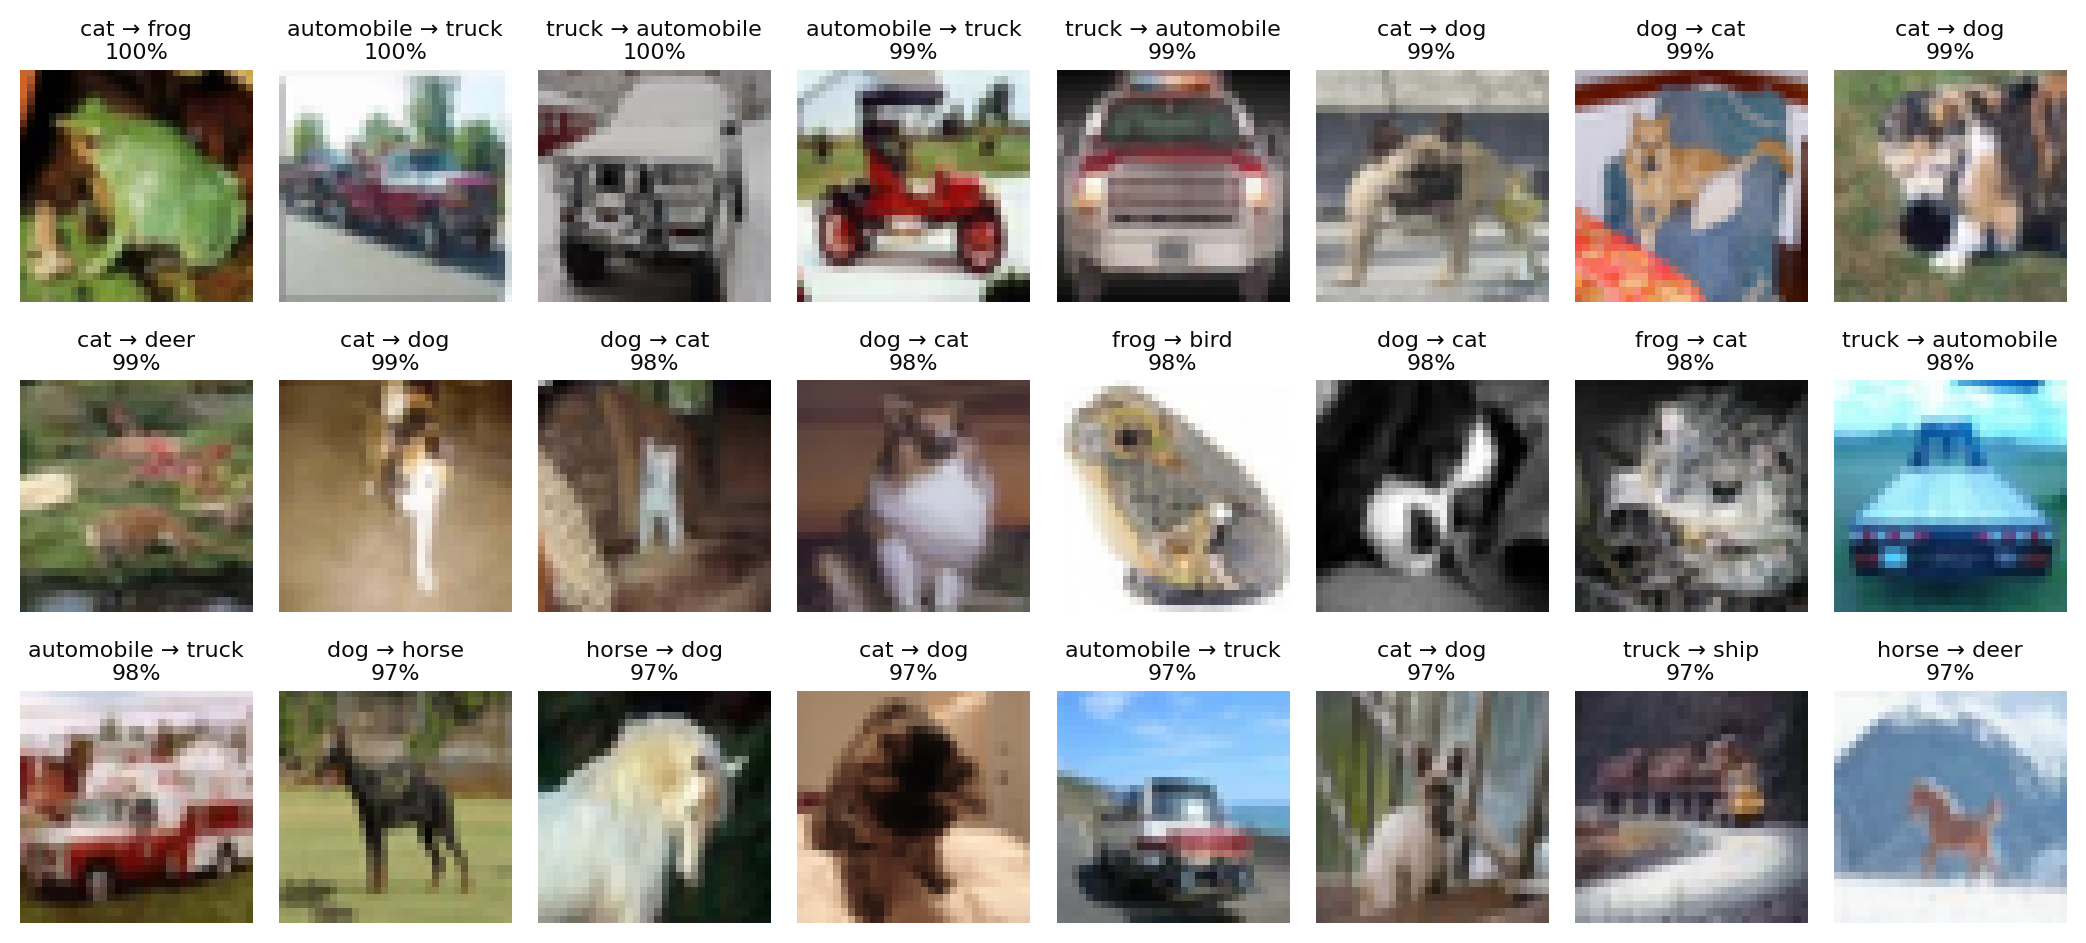

In [9]:
raw_test = cifar10("data", train=False).data
wrong = torch.where(~correct)[0]
worst = wrong[confidence[wrong].argsort(descending=True)][:24].tolist()
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(3, 8, figsize=(10.5, 4.9))
    for ax, i in zip(axes.flat, worst):
        ax.imshow(raw_test[i], interpolation="nearest")
        ax.set_title(f"{CLASSES[test_y[i]]} → {CLASSES[prediction[i]]}\n{100 * confidence[i]:.0f}%", fontsize=8,
                     fontweight="normal", loc="center", color=INK, pad=4)
        ax.axis("off")
    fig.tight_layout(h_pad=1.2)
    plt.show()

### Accuracy by subgroup size

Each class of the training set was split into 20 subgroups by k-means on the features of our LeJEPA teacher (report, *Subgroups Discovered with JEPA*). Each test image is assigned to the nearest subgroup of its true class, and the subgroups are split into three equal groups by their number of training images.

In [10]:
subgroups_dir = "results/subgroups_38_teacher_wrn28_10_lejepa_full/20261101-160050"
test_groups = pd.read_csv(f"{subgroups_dir}/test_subgroups.csv", index_col=0)
groups = pd.read_csv(f"{subgroups_dir}/subgroups.csv", index_col=0)
size = groups.size_tercile.values[test_groups.subgroup.values]
rows = []
for tercile in ["rare", "medium", "common"]:
    inside = size == tercile
    rows.append((f"{tercile.capitalize()} third", 100 * groups.train_size[groups.size_tercile == tercile].sum() / 50000,
                 100 * inside.mean(), 100 * ok[inside].mean(), 100 * (~ok & inside).sum() / (~ok).sum()))
show(pd.DataFrame(rows, columns=["Subgroups", "Training images (%)", "Test images (%)", "Test accuracy, TTA (%)",
                                 "Share of the errors (%)"]), "Test accuracy by subgroup size")

Subgroups,Training images (%),Test images (%),"Test accuracy, TTA (%)",Share of the errors (%)
Rare third,21.25,28.89,93.18,86.78
Medium third,32.45,31.34,99.17,11.45
Common third,46.30,39.77,99.90,1.76


## Part 2 · Results discussed in the report

Each section below matches a section of the report. Everything is read from `logs/`, which holds one folder per trained model (console output, per-epoch and per-step metrics, and a `summary.json` with hyperparameters and final metrics), and from `results/`, which holds the analysis tables. The figures come from `report/make_figures.py`, the code that draws the report's figures. The report's figure of Kaggle public scores is left out, since this notebook does not use Kaggle data.

Two of our models typically differ on 100 to 130 test images, so a gap between them has a standard error of about 0.1 points; the report treats smaller gaps as ties.

### Choosing the optimizer

A small AirBench (64, 256 and 256 channels, 3,188,440 parameters, no distillation) trained with each optimizer at three learning rates, on the 45k images, on the laptop GPU. Each row uses the learning rate best on the validation set and averages two seeds. AdamW trails SGD. Muon leads at 10 epochs, but its lead shrinks with training length and each run takes longer, so we kept SGD for our 300- to 1200-epoch runs.

In [11]:
optim = pd.read_csv(sorted(glob.glob("logs/63_optimizer_comparison/*/best.csv"))[-1])
rows = []
for key, name in [("sgd", "SGD"), ("muon", "Muon"), ("adamw", "AdamW")]:
    r = optim[optim.optimizer == key].set_index("epochs")
    rows.append((name, r.lr.iloc[0], 100 * r.test_tta_acc[10], 100 * r.test_tta_acc[30], r.time_s[10], r.time_s[30]))
columns = ["Optimizer", "Learning rate", "Test TTA, 10 epochs (%)", "Test TTA, 30 epochs (%)",
           "Seconds per run, 10 epochs", "Seconds per run, 30 epochs"]
show(pd.DataFrame(rows, columns=columns), "Optimizers on a small AirBench",
     formats={"Learning rate": "{:g}", columns[4]: "{:.0f}", columns[5]: "{:.0f}"},
     best_in_column=["Test TTA, 10 epochs (%)", "Test TTA, 30 epochs (%)"])

Optimizer,Learning rate,"Test TTA, 10 epochs (%)","Test TTA, 30 epochs (%)","Seconds per run, 10 epochs","Seconds per run, 30 epochs"
SGD,9,92.63,95.01,23,64
Muon,0.12,93.54,95.35,33,71
AdamW,0.004,90.33,94.01,25,64


### AirBench versus Wide ResNet

Both families under matching conditions: the same teacher (a WRN-28-10 trained with SAM on the 45k images), the same 45k images, and Mixup with CutMix. Every Wide ResNet beats AirBench at every training length, at 2.3 to 2.7 times the training time, and neither family gains beyond 600 epochs with a single teacher.

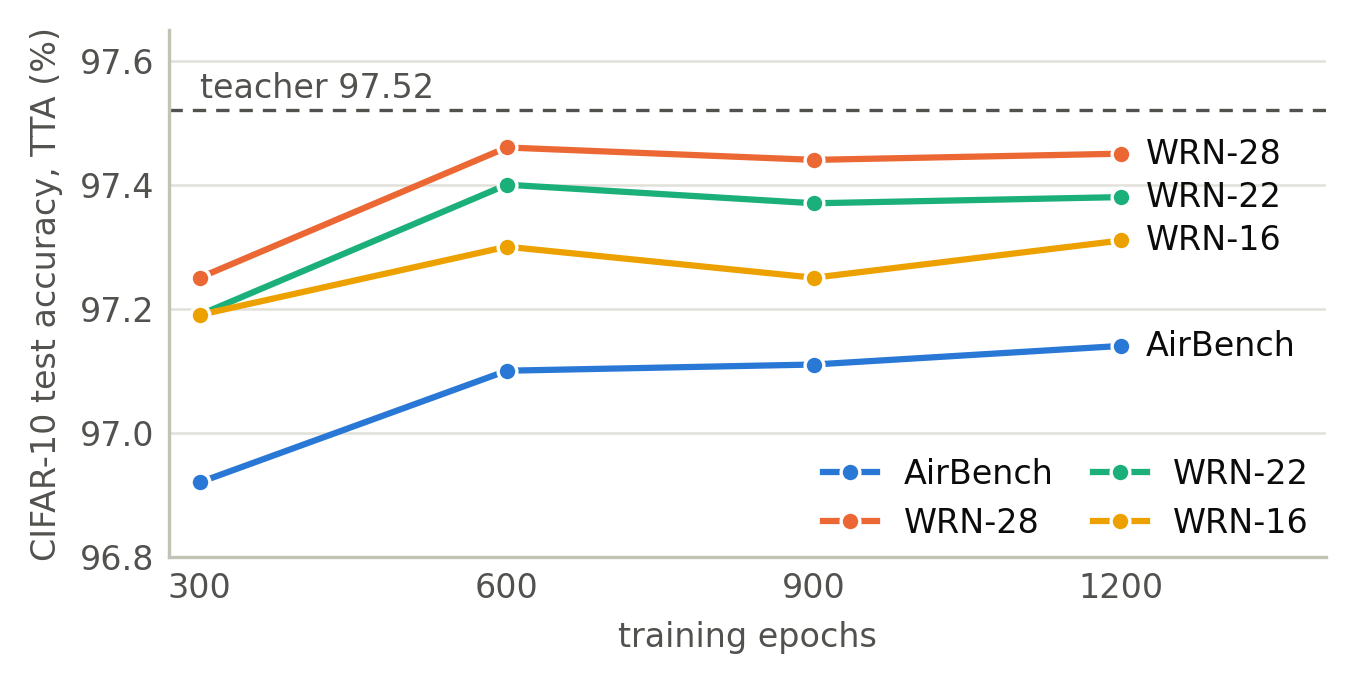

Model,Channels,Blocks per stage,Parameters,Hours (A100),Test TTA (%)
AirBench,"128, 256, 352",1,"4,844,152",0.63,97.10
WRN-28,"58, 116, 232",4,"4,805,542",1.67,97.46
WRN-22,"68, 136, 272",3,"4,851,866",1.55,97.40
WRN-16,"86, 172, 344",2,"4,955,622",1.45,97.30


In [12]:
show_figure(figures.students_by_epochs())

archs = [("AirBench", "128, 256, 352", 1, "10_kd_mix_600ep"), ("WRN-28", "58, 116, 232", 4, "25_wrn28_w58_kd_600ep"),
         ("WRN-22", "68, 136, 272", 3, "26_wrn22_w68_kd_600ep"), ("WRN-16", "86, 172, 344", 2, "27_wrn16_w86_kd_600ep")]
rows = [(name, channels, blocks, summary(run)["n_params"], summary(run)["train_time_s"] / 3600, test_tta(run))
        for name, channels, blocks, run in archs]
show(pd.DataFrame(rows, columns=["Model", "Channels", "Blocks per stage", "Parameters", "Hours (A100)",
                                 "Test TTA (%)"]),
     "Student architectures, 600 epochs with the 45k teacher", best_in_column=["Test TTA (%)"])

Depth against width: every experiment in which we trained the three Wide ResNet students under identical conditions. Within a row they stay within 0.29 points; WRN-16, with two blocks per stage, never comes first.

In [13]:
plain = "45k teacher"
rows = [("45k", plain, "–", e, [f"{p}_{a}_kd_{e}ep" if e > 300 else f"{q}_{a}_kd"
                                for p, q, a in [("25", "16", "wrn28_w58"), ("26", "17", "wrn22_w68"),
                                                ("27", "18", "wrn16_w86")]]) for e in [300, 600, 900, 1200]]
rows += [("45k", plain, "SE", e, [f"40_wrn28_w58_se_kd_{e}ep", f"41_wrn22_w68_se_kd_{e}ep", f"42_wrn16_w86_se_kd_{e}ep"])
         for e in [600, 900]]
three = [("43", "wrn28_w58"), ("44", "wrn22_w68"), ("45", "wrn16_w86")]
rows += [("50k", "3-teacher", "–", 600, [f"{i}_{a}_full_t35_37_38_600ep" for i, a in three]),
         ("50k", "3-teacher", "SAM", 600, [f"{i}_{a}_full_t35_37_38_600ep_sam" for i, a in three]),
         ("50k", "3-teacher", "Std. logits, T = 2", 600,
          [f"{i}_{a}_full_t35_37_38_600ep_lstd" for i, a in [("46", "wrn28_w58"), ("47", "wrn22_w68"), ("48", "wrn16_w86")]]),
         ("50k", "3-teacher", "Sampler", 600,
          [f"{i}_{a}_full_t35_37_38_600ep_sqrtw" for i, a in [("49", "wrn28_w58"), ("50", "wrn22_w68"), ("51", "wrn16_w86")]]),
         ("50k", "Final", "Sampler", 600,
          [f"{i}_{a}_full_t35_38_55_56_600ep_sqrtw" for i, a in [("57", "wrn28_w58"), ("58", "wrn22_w68"), ("59", "wrn16_w86")]]),
         ("50k", "Final", "Sampler", 1200,
          ["60_wrn28_w58_full_t35_38_55_56_1200ep_sqrtw", "61_wrn22_w68_full_t35_38_55_56_1200ep_sqrtw", None])]
table = pd.DataFrame([(data, teachers, change, epochs,
                       *[np.nan if run is None else test_tta(run) for run in runs])
                      for data, teachers, change, epochs, runs in rows],
                     columns=["Data", "Teachers", "Change", "Epochs", "WRN-28", "WRN-22", "WRN-16"])
students = ["WRN-28", "WRN-22", "WRN-16"]
complete = table.dropna(subset=students)
table.loc[len(table)] = [f"Mean over the {len(complete)} complete rows", "", "", np.nan, *complete[students].mean()]
show(table, "Test TTA accuracy (%) of the three students", formats={"Epochs": "{:.0f}"}, best_in_row=students)

Data,Teachers,Change,Epochs,WRN-28,WRN-22,WRN-16
45k,45k teacher,–,300,97.25,97.19,97.19
45k,45k teacher,–,600,97.46,97.40,97.30
45k,45k teacher,–,900,97.44,97.37,97.25
45k,45k teacher,–,1200,97.45,97.38,97.31
45k,45k teacher,SE,600,97.46,97.25,97.32
45k,45k teacher,SE,900,97.41,97.32,97.30
50k,3-teacher,–,600,97.73,97.51,97.44
50k,3-teacher,SAM,600,97.53,97.42,97.34
50k,3-teacher,"Std. logits, T = 2",600,97.47,97.65,97.47
50k,3-teacher,Sampler,600,97.67,97.67,97.60


### Ensemble distillation

The six teachers trained on all 50k images. *Shared errors* is the share of SAM-1's test errors that a teacher also makes. The CCT, a small transformer, is the weakest teacher alone and the one whose errors differ most, and every ensemble containing it beats every ensemble without it.

Teacher,Model and training,Test TTA (%),Shared errors with SAM-1 (%)
SAM-1,"WRN-28-10, SAM",97.53,–
SAM-2,"WRN-28-10, SAM, second seed",97.62,78.05
SimCLR,"WRN-28-10, SimCLR pretraining, then fine-tuning",97.42,70.73
LeJEPA,"WRN-28-10, LeJEPA pretraining, then fine-tuning",97.56,67.89
SAM-AA,"WRN-28-10, SAM paper recipe with AutoAugment",97.60,75.61
CCT,"CCT-7/3×1, sinusoidal position embeddings",97.24,52.03


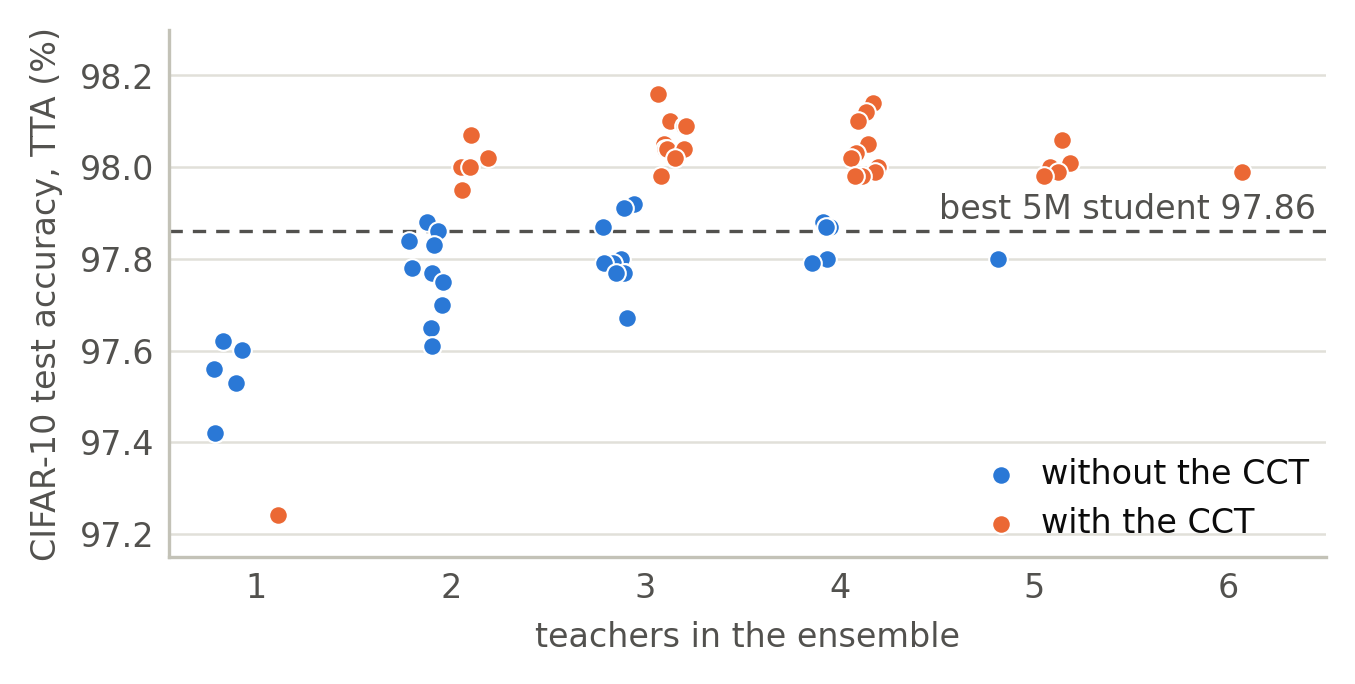

In [14]:
teachers = latest("teacher_ensembles_with_56", "teachers")
recipes = {"34": "WRN-28-10, SAM", "35": "WRN-28-10, SAM, second seed",
           "37": "WRN-28-10, SimCLR pretraining, then fine-tuning", "38": "WRN-28-10, LeJEPA pretraining, then fine-tuning",
           "55": "WRN-28-10, SAM paper recipe with AutoAugment", "56": "CCT-7/3×1, sinusoidal position embeddings"}
ids = teachers.teacher.astype(str)
shared = teachers["share of 34's errors also made (%)"].where(ids != "34")
show(pd.DataFrame({"Teacher": ids.map(TEACHER_NAMES), "Model and training": ids.map(recipes),
                   "Test TTA (%)": [test_tta(f"{t}_teacher_*") for t in ids], "Shared errors with SAM-1 (%)": shared}),
     "Teachers trained on all 50k images", left=["Model and training"])
show_figure(figures.ensembles())

### Subgroups discovered with JEPA

Each class's 5,000 training images are split into 20 subgroups by spherical k-means on the LeJEPA teacher's features. Each panel below is a UMAP of one class; dark points are the rarest third of subgroups, and orange points are the test images that the final WRN-28 misclassifies. About 89% of student errors fall in the rarest third. Drawing those images more often (probability ∝ 1/√size) moved them by 0.33 points on average, but overall accuracy only by 0.09 points, within noise.

test errors of the final WRN-28 in rare subgroups: 207 of 231


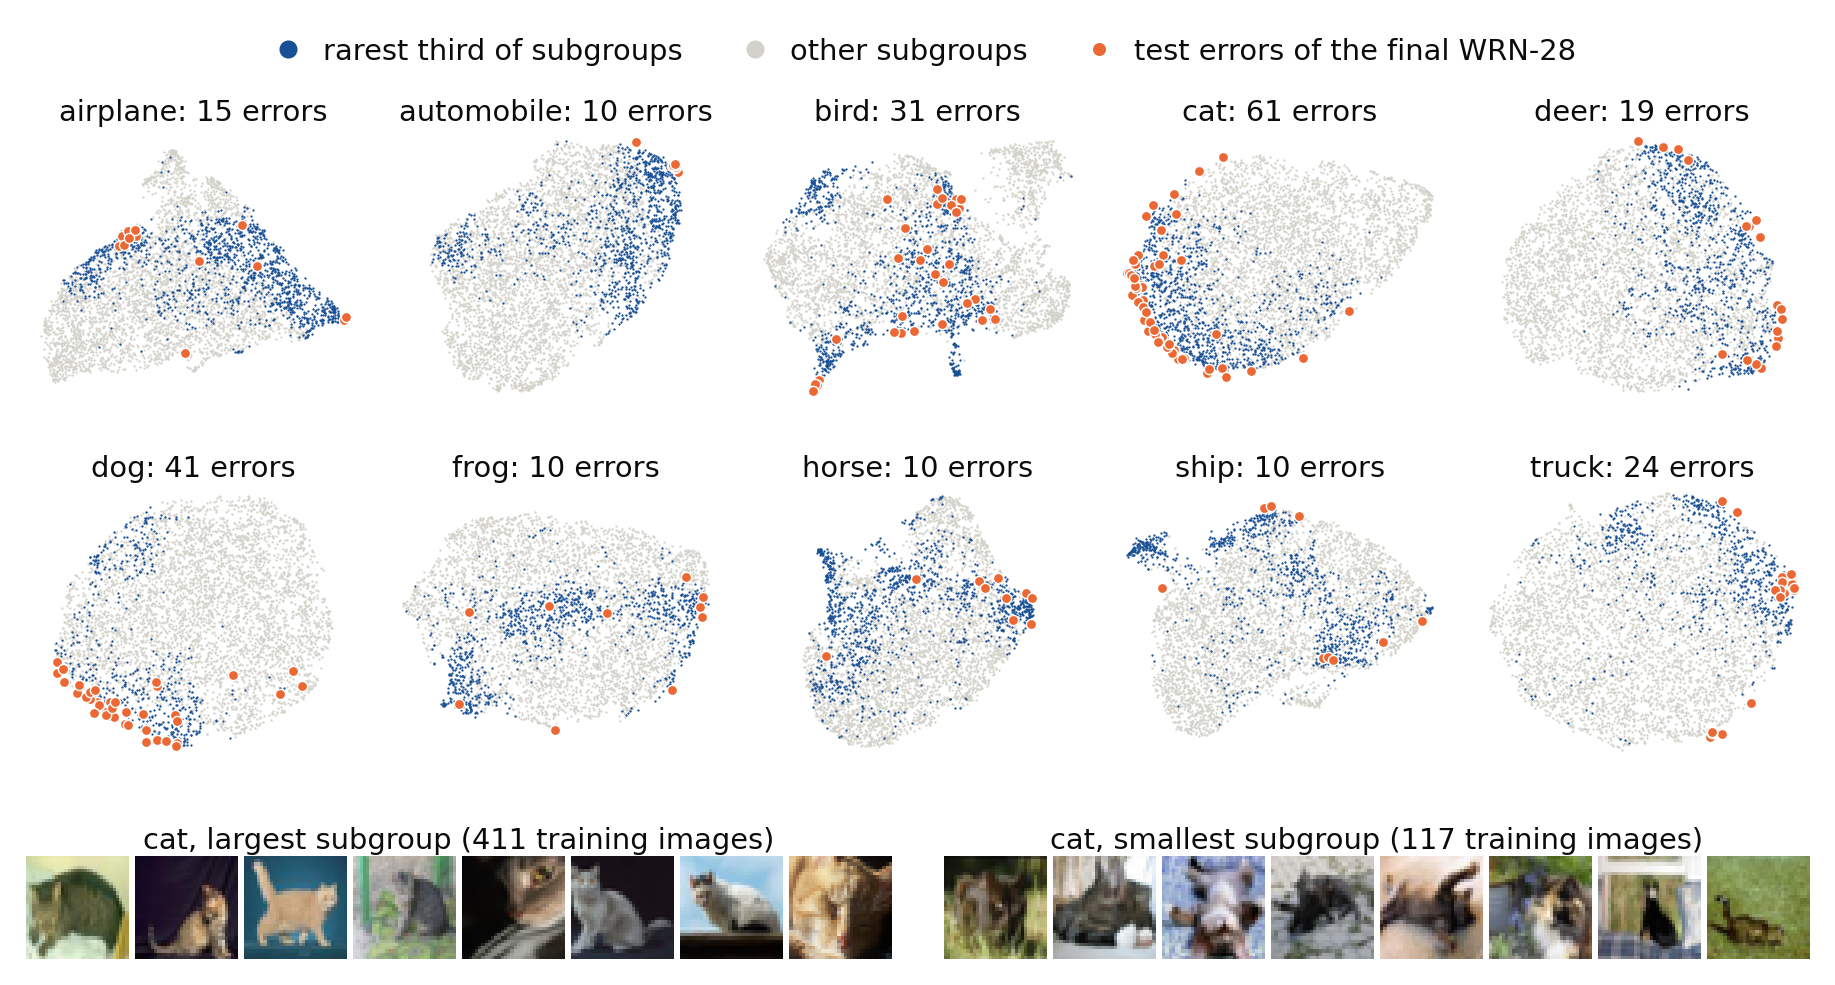

Subgroups,Training images (%),Test images (%),No sampler,Sampler
Rare third,21.25,28.89,92.47,92.80
Medium third,32.45,31.34,99.22,99.21
Common third,46.30,39.77,99.95,99.93
All images,100.00,100.00,97.56,97.65


In [15]:
show_figure(figures.subgroups(), dpi=130)

by_size = latest("subgroups_38_teacher_wrn28_10_lejepa_full", "accuracy_by_size")
plain = [c for c in by_size if c.startswith("test_acc_") and not c.endswith("sqrtw (%)")]
sampler = [c for c in by_size if c.endswith("sqrtw (%)")]
table = pd.DataFrame({"Subgroups": by_size.size_tercile.str.capitalize() + " third",
                      "Training images (%)": 100 * by_size["train images"] / by_size["train images"].sum(),
                      "Test images (%)": 100 * by_size["test images"] / by_size["test images"].sum(),
                      "No sampler": by_size[plain].mean(1), "Sampler": by_size[sampler].mean(1)})
overall = [np.mean([test_tta(f"{i}_{a}_full_t35_37_38_600ep{s}") for i, a in runs])
           for s, runs in [("", [("43", "wrn28_w58"), ("44", "wrn22_w68"), ("45", "wrn16_w86")]),
                           ("_sqrtw", [("49", "wrn28_w58"), ("50", "wrn22_w68"), ("51", "wrn16_w86")])]]
table.loc[len(table)] = ["All images", 100, 100, *overall]
show(table, "Test accuracy (%) by subgroup size, mean of the three students distilled from the 3-teacher ensemble")

**Which teacher is the expert where.** The CCT is not stronger on rare subgroups, and it is the weakest teacher on common ones. What sets it apart is which images it gets right: of the test images that all three Wide ResNet teachers of the final ensemble misclassify, it gets far more right than the two other Wide ResNet teachers. Choosing teachers per class or per subgroup, fitted on one half of the test set and scored on the other, does worse than one choice for all images, so plain averaging is the right way to combine them.

In [16]:
NAMES = {"final ensemble": "Final ensemble", "final WRN-28": "Final WRN-28 (57)"}
experts = latest("teacher_experts", "accuracy").replace({"model": NAMES})
show(experts[["model", "rare", "medium", "common", "errors in rare (%)"]].rename(columns={
         "model": "Model", "rare": "Rare third (%)", "medium": "Medium third (%)",
         "common": "Common third (%)", "errors in rare (%)": "Errors in the rare third (%)"}),
     "Test TTA accuracy by subgroup size, for every teacher, the final ensemble and the final WRN-28")

rescues = latest("teacher_experts", "rescues").replace({"model": NAMES})
blind = rescues.iloc[0]
show(rescues.iloc[1:][["model", "all", "rare", "medium", "common"]].rename(columns={
         "model": "Model", "all": f"All ({blind['all']})", "rare": f"Rare ({blind['rare']})",
         "medium": f"Medium ({blind['medium']})", "common": f"Common ({blind['common']})"}),
     "Test images that SAM-2, LeJEPA and SAM-AA all misclassify (count in each header): how many each model gets right")

routing = latest("teacher_experts", "routing")
show(pd.DataFrame({"Teachers chosen": routing.granularity.str.replace("predicted", "per predicted").str.capitalize(),
                   "Accuracy on the half used to choose (%)": routing["routed, same half mean"],
                   "Accuracy on the other half (%)": routing["routed, other half mean"],
                   "Average of all six on the other half (%)": routing["all six averaged mean"]}),
     "Choosing teacher subsets on one half of the test set, scored on the other (mean of 200 splits)",
     best_in_column=["Accuracy on the other half (%)"])

Model,Rare third (%),Medium third (%),Common third (%),Errors in the rare third (%)
SAM-1,92.52,99.11,99.95,87.80
SAM-2,92.63,99.30,99.92,89.50
SimCLR,92.14,99.07,99.95,87.98
LeJEPA,92.56,99.14,99.95,88.11
SAM-AA,92.66,99.17,99.92,87.97
CCT,92.49,98.50,99.70,78.62
Final ensemble,94.25,99.43,99.95,89.25
Final WRN-28 (57),92.83,99.30,99.95,89.61


Model,All (142),Rare (126),Medium (14),Common (2)
SAM-1,11,10,1,0
SimCLR,18,16,2,0
CCT,52,45,6,1
Final ensemble,18,17,1,0
Final WRN-28 (57),15,14,1,0


Teachers chosen,Accuracy on the half used to choose (%),Accuracy on the other half (%),Average of all six on the other half (%)
One subset for all,98.11,98.08,97.99
Per predicted subgroup size,98.10,98.06,97.99
Per predicted class,98.21,98.03,97.99
Per predicted class and size,98.29,98.01,97.99
Per predicted subgroup,98.53,97.87,97.99


### How much of an ensemble can a student absorb?

On clean training images the teachers almost never disagree, but students train on Mixup and CutMix images, where at least one teacher disagrees on almost a quarter of the inputs. The students have not finished fitting those: their distillation loss there stays above the loss on test images.

In [17]:
inputs = latest("student_fidelity_analysis", "teacher_disagreement_by_input")
show(pd.DataFrame({"Inputs": ["Clean training images", "Training, flip, translation, Cutout",
                              "Training, Mixup or CutMix (student input)", "Test images"],
                   "A teacher disagrees (%)": inputs["any teacher disagrees (%)"],
                   "WRN-28 (57) agrees (%)": inputs["57 agree (%)"], "WRN-28 KD loss": inputs["57 KD loss"],
                   "WRN-22 (58) agrees (%)": inputs["58 agree (%)"], "WRN-22 KD loss": inputs["58 KD loss"]}),
     "The four teachers of the final ensemble and the final students, without TTA",
     formats={"WRN-28 KD loss": "{:.3f}", "WRN-22 KD loss": "{:.3f}"})

Inputs,A teacher disagrees (%),WRN-28 (57) agrees (%),WRN-28 KD loss,WRN-22 (58) agrees (%),WRN-22 KD loss
Clean training images,0.25,99.92,0.052,99.92,0.054
"Training, flip, translation, Cutout",3.57,98.83,0.094,98.79,0.106
"Training, Mixup or CutMix (student input)",23.79,94.45,0.123,94.33,0.127
Test images,4.73,98.81,0.082,98.83,0.080


### Final results and where the accuracy came from

The final students, trained on all 50k images with the final ensemble and the subgroup sampler. The two 600-epoch students were our final submissions; this notebook's model is the WRN-22.

In [18]:
final = [("WRN-28", "57_wrn28_w58_full_t35_38_55_56_600ep_sqrtw", "yes"),
         ("WRN-22", "58_wrn22_w68_full_t35_38_55_56_600ep_sqrtw", "yes"),
         ("WRN-28", "60_wrn28_w58_full_t35_38_55_56_1200ep_sqrtw", "no"),
         ("WRN-22", "61_wrn22_w68_full_t35_38_55_56_1200ep_sqrtw", "no")]
rows = [(name, summary(run)["n_params"], summary(run)["hyp"]["epochs"], 100 * summary(run)["test_acc"], test_tta(run),
         summary(run)["train_time_s"] / 3600, submitted) for name, run, submitted in final]
show(pd.DataFrame(rows, columns=["Model", "Parameters", "Epochs", "Test (%)", "Test TTA (%)", "Hours (A100)",
                                 "Submitted"]), "Final students", formats={"Epochs": "{:d}"}, best_in_column=["Test TTA (%)"])

Model,Parameters,Epochs,Test (%),Test TTA (%),Hours (A100),Submitted
WRN-28,"4,805,542",600,97.68,97.69,3.61,yes
WRN-22,"4,851,866",600,97.58,97.74,3.53,yes
WRN-28,"4,805,542",1200,97.72,97.78,7.54,no
WRN-22,"4,851,866",1200,97.80,97.86,7.26,no


From our first AirBench run to the final WRN-28, one change at a time where our runs allow it. Longer training, distillation and the switch to a Wide ResNet gave most of the 2.12 points; the subgroup sampler and the final ensemble are ties for this student.

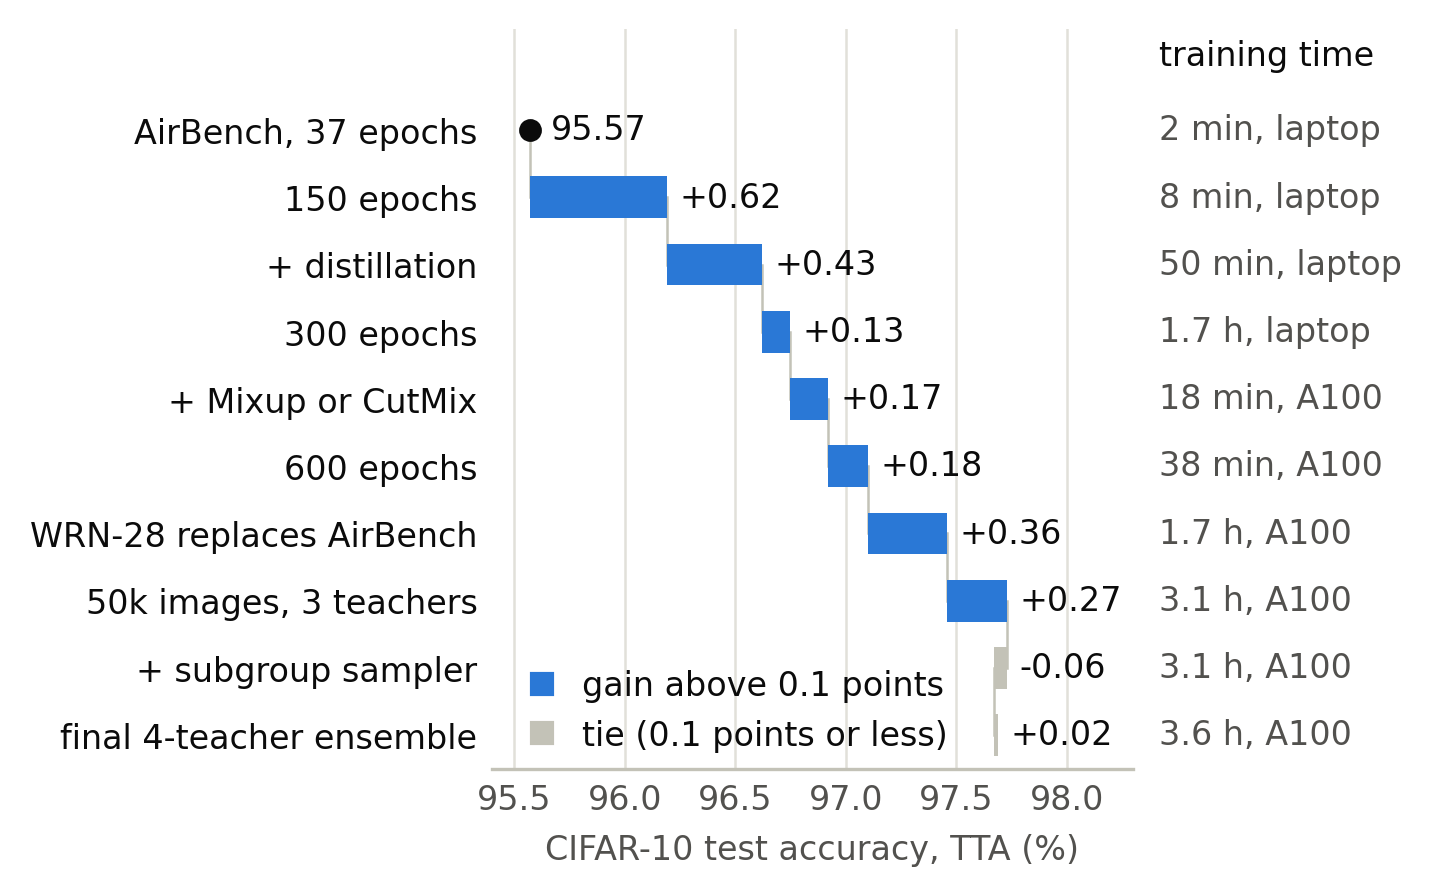

In [19]:
show_figure(figures.ladder())

## Lessons

- **Measure on the inputs a model actually trains on.** On clean images our students looked saturated; on the mixed images they train on, they were not.
- **Look for teachers that are wrong in different ways**, not for slightly stronger ones: the weakest teacher, the only transformer, lifted every ensemble it joined.
- **Compute the noise first.** Many of the gaps we chased were smaller than the noise of the set measuring them.

The README explains how to retrain every model and where each log is.